**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**03 | Participant-Grouped Unimodal Movement Classification**

![Source-aligned sEMG and acceleration, classical baselines, CNN/TCN/BiGRU encoders and grouped Development evaluation](../../images/03_unimodal_grouped_baselines.svg)

**Research question:** How do sEMG-only and acceleration-only classical and temporal classifiers compare when evaluated on the same previously unseen Development participants?

**Inputs:** The fixed NinaPro DB2 E1 **40,000 paired windows** from Notebook 02, with **35 Development participants (35,000 windows)** and **five reserved Test participants**. Each observation has one of **18 original corrected source labels (0–17)**.

**Study design:** Five participant-disjoint Development folds evaluate a majority-prior baseline, two Logistic Regression models, two Random Forest models and six 1D-CNN/TCN/BiGRU unimodal architectures. Feature scaling and neural early stopping use permitted Training participants only.

**Primary metric:** Macro F1 is calculated with the fixed 18-class label set for each Validation participant, then averaged **equally across people**. Results from the same Development folds support model selection; they are not an independent final Test estimate.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------------- 4. Deep Learning and Compute Device --------------------
from core.computer_device import computer_device
device = computer_device(min_vram_gb=None)

# ------------------------ 5. Study Research Utilities ------------------------
from ninapro_dataset import ensure_numerical_cache
from ninapro_evaluation import select_model, predictions_from_probabilities
from ninapro_models import UNIMODAL_MODELS
from ninapro_experiments import (
    CLASSICAL_MODELS, run_classical_arm, run_unimodal_arm,
    consolidate_unimodal_outputs, evaluate_finalist_seeds,
    consolidate_seed_robustness,
)

# ---------------------- 6. Source and Output Locations -----------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository updated.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Read Fixed Classes and Paired Development Windows**

Read the window identities, corrected source labels and participant assignments established in Notebook 02. The reserved five Test participants are excluded before any model fitting; all eleven models are assessed on the same five Development validation folds.

The Training and Validation partitions never share a participant, even though adjacent windows may overlap within an individual source recording.


In [3]:
# =========== 02. Read Fixed Classes and Paired Development Windows ===========

NOTEBOOK_NUMBER = 3
index = pd.read_csv(output_dir / "02_window_index.csv")
roles = pd.read_csv(output_dir / "02_participant_split_assignments.csv")
folds = pd.read_csv(output_dir / "02_development_fold_assignments.csv")
classes = np.sort(pd.read_csv(output_dir / "01_label_dictionary.csv").label.to_numpy(int))
role_map = dict(zip(roles.subject_id, roles.role))
fold_map = dict(zip(folds.subject_id, folds.validation_fold))
index["role"] = index.subject_id.map(role_map)
index["validation_fold"] = index.subject_id.map(fold_map)
if index.role.isna().any() or index.loc[index.role == "Development", "validation_fold"].isna().any():
    raise ValueError("Incomplete Notebook 02 person/fold assignments.")

dev = index.loc[index.role == "Development"].copy()
assert not set(dev.subject_id) & set(roles.loc[roles.role == "Test", "subject_id"])
print("Development people:", dev.subject_id.nunique(), "| windows:", len(dev))
print("Independent Development folds:", sorted(dev.validation_fold.unique()))


Development people: 35 | windows: 35000
Independent Development folds: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]


**03. Recover Aligned Statistical and Temporal Inputs**

Reuse the paired numerical representations established in Notebook 02: **48 statistical sEMG features** and **96 acceleration features** per window, together with the **600-row temporal recordings** required by the CNN, TCN and BiGRU models.

The cache check first reports how many per-participant sensor arrays and feature matrices are present in the active Colab repository. Existing compatible arrays are reused; only missing source arrays or invalid/missing feature files require reconstruction. If source recovery is needed, each affected participant is reported before the potentially lengthy archive retrieval.

Both modalities retain the same canonical `window_row` ordering. Feature scaling and neural normalisation are fitted **within Training participants** at the model-training stage; no global cohort-level scaler is fitted here.


In [4]:
# ============ 03. Recover Aligned Statistical and Temporal Inputs ============

emg_features, acc_features = ensure_numerical_cache(
    root, index, allow_source_download=True, verbose=True,
)
print("Feature array shapes:", emg_features.shape, acc_features.shape)
print("Fixed task classes:", classes.tolist())


Numerical cache directory: /content/human-movement-intelligence/data/processed/ninapro_db2
Paired E1 source arrays: 40/40 participants present.
Statistical feature files: sEMG=available, Acc=available.
Validated paired source arrays for 40 participants.
Reused both saved statistical feature arrays; no feature extraction required.
Feature array shapes: (40000, 48) (40000, 96)
Fixed task classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


**04. Shared Development Protocol**

Use the same corrected label set, participant folds and primary seed (`42`) for all experiments. Classical models use Training-only scaling as appropriate. Neural networks use a Training-only inner participant split to choose the checkpoint, never the outer Validation participants.

Long-running models execute independently and preserve fold-specific scores and prediction identities. A consolidated Development comparison is constructed only after all model cells have completed.

**Training throughput:** Each temporal model reads only its required sensor modality from the existing memory-mapped source arrays. On CUDA, the DataLoader uses two prefetch workers and pinned-memory transfers, while window indices are kept in compact NumPy arrays. The training loop reports the selected loader settings and epoch duration. These engineering changes do not reduce the five folds, ten-epoch maximum, participant-grouped evaluation or original temporal windows; their effect on runtime must be measured during execution.


In [5]:
# ====================== 04. Shared Development Protocol ======================

SEED = 42
NEURAL_EPOCHS = 10
NEURAL_PATIENCE = 3
NEURAL_BATCH_SIZE = 96
common_folds = sorted(dev.validation_fold.dropna().unique().astype(int).tolist())

print("Classical models:", ", ".join(CLASSICAL_MODELS))
print("Neural models:", ", ".join(UNIMODAL_MODELS))
print("Grouped Development folds:", common_folds)
print("Training epochs (maximum):", NEURAL_EPOCHS)


Classical models: B0_prior, B1_logreg, B1_rf, B2_logreg, B2_rf
Neural models: D1_emg_cnn, D1_acc_cnn, D2_emg_tcn, D2_acc_tcn, D3_emg_bigru, D3_acc_bigru
Grouped Development folds: [0, 1, 2, 3, 4]
Training epochs (maximum): 10


**05. B0: Training-Prior Baseline**

This no-signal reference estimates class priors from Training labels and predicts without using either sensor. Its fold-wise macro F1 provides a necessary baseline for interpreting sensor-dependent performance; it does not represent a clinical or movement-aware classifier.


In [6]:
# ====================== 05. B0: Training-Prior Baseline ======================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B0_prior", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B0_prior | modality: Training prior | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.0335 | 0.0 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.0376 | 0.0 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.0329 | 0.0 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.0349 | 0.0 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.0360 | 0.0 s
B0_prior | equal-participant Development macro F1: 0.0350


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.033499,0.021227
1,1,7,0.037590,0.013241
2,2,7,0.032872,0.016568
3,3,7,0.034879,0.006968
4,4,7,0.036016,0.023095


**06. B1: sEMG Logistic Regression**

Logistic Regression uses the **48 sEMG statistical features** with a Training-fitted standard scaler and balanced class weights. The `lbfgs` solver must reach numerical convergence before its predictions enter the Development comparison. The number of solver iterations is recorded per fold.


In [7]:
# ===================== 06. B1: sEMG Logistic Regression ======================

#  Participant-Grouped Model Fit
display(run_classical_arm(
    "B1_logreg", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B1_logreg | modality: sEMG | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1575 | 14.9 s | converged in 317 iterations
  Fold 2/5 | 7 validation people | mean participant macro F1 0.1902 | 15.1 s | converged in 285 iterations
  Fold 3/5 | 7 validation people | mean participant macro F1 0.2254 | 17.4 s | converged in 301 iterations
  Fold 4/5 | 7 validation people | mean participant macro F1 0.2531 | 15.9 s | converged in 308 iterations
  Fold 5/5 | 7 validation people | mean participant macro F1 0.2159 | 15.6 s | converged in 299 iterations
B1_logreg | equal-participant Development macro F1: 0.2084


,validation_fold,participants,macro_f1,fit_seconds,solver_iterations
0,0,7,0.157546,14.910489,317
1,1,7,0.190164,15.053407,285
2,2,7,0.225351,17.391526,301
3,3,7,0.253074,15.885407,308
4,4,7,0.215921,15.617556,299


**07. B1: sEMG Random Forest**

The 48-feature sEMG representation is assessed using a class-weighted 120-tree Random Forest. The source windows and independent participant folds are identical to those used by Logistic Regression; no Test data contribute to fitting or comparison.


In [8]:
# ======================== 07. B1: sEMG Random Forest =========================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B1_rf", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B1_rf | modality: sEMG | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1794 | 34.7 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.2576 | 32.0 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.2481 | 33.7 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.2541 | 31.2 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.2350 | 32.3 s
B1_rf | equal-participant Development macro F1: 0.2348


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.179359,34.700775
1,1,7,0.257636,31.953222
2,2,7,0.248078,33.740065
3,3,7,0.254077,31.154955
4,4,7,0.235029,32.327598


**08. B2: Acceleration Logistic Regression**

The acceleration-only Logistic Regression receives the **96 statistical acceleration features**. It uses the same regularisation, numerical convergence checks, Training-only standardisation and grouped folds as the sEMG variant.


In [9]:
# ================= 08. B2: Acceleration Logistic Regression ==================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B2_logreg", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B2_logreg | modality: Acceleration | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.0767 | 30.9 s | converged in 523 iterations
  Fold 2/5 | 7 validation people | mean participant macro F1 0.0833 | 35.0 s | converged in 543 iterations
  Fold 3/5 | 7 validation people | mean participant macro F1 0.0915 | 36.4 s | converged in 539 iterations
  Fold 4/5 | 7 validation people | mean participant macro F1 0.1472 | 36.7 s | converged in 517 iterations
  Fold 5/5 | 7 validation people | mean participant macro F1 0.1186 | 34.9 s | converged in 509 iterations
B2_logreg | equal-participant Development macro F1: 0.1034


,validation_fold,participants,macro_f1,fit_seconds,solver_iterations
0,0,7,0.076674,30.893143,523
1,1,7,0.083292,34.965371,543
2,2,7,0.091470,36.428881,539
3,3,7,0.147195,36.703522,517
4,4,7,0.118580,34.913204,509


**09. B2: Acceleration Random Forest**

A 120-tree Random Forest uses only the acceleration feature matrix. Its validation participants, scoring classes and metric aggregation are unchanged, so modality comparisons do not depend on different data partitions.


In [10]:
# ==================== 09. B2: Acceleration Random Forest =====================

# Participant-Grouped Model Fit 
display(run_classical_arm(
    "B2_rf", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B2_rf | modality: Acceleration | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1308 | 50.4 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.1144 | 52.8 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.1326 | 49.9 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.1319 | 50.6 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.1353 | 50.3 s
B2_rf | equal-participant Development macro F1: 0.1290


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.130753,50.390940
1,1,7,0.114388,52.764744
2,2,7,0.132585,49.931002
3,3,7,0.131860,50.615161
4,4,7,0.135303,50.346350


**10. D1: sEMG-Only 1D-CNN**

A compact three-stage 1D-CNN learns local temporal patterns from the **12 sEMG channels**. Its Training-only inner holdout selects the checkpoint; each outer fold reports seven independent Validation participants. Acceleration is excluded from its predictive inputs.



Model: D1_emg_cnn | modality: sEMG | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Data loader: emg only | workers=2 | pinned memory=True | batch size=96
  D1_emg_cnn | seed=42 | epoch 1/10 | loss=2.5883 | inner macro F1=0.1927 | 13.5 s
  D1_emg_cnn | seed=42 | epoch 2/10 | loss=2.3447 | inner macro F1=0.2084 | 3.3 s
  D1_emg_cnn | seed=42 | epoch 3/10 | loss=2.2486 | inner macro F1=0.2312 | 3.3 s
  D1_emg_cnn | seed=42 | epoch 4/10 | loss=2.1868 | inner macro F1=0.2477 | 3.7 s
  D1_emg_cnn | seed=42 | epoch 5/10 | loss=2.1369 | inner macro F1=0.2538 | 3.7 s
  D1_emg_cnn | seed=42 | epoch 6/10 | loss=2.0982 | inner macro F1=0.2573 | 3.2 s
  D1_emg_cnn | seed=42 | epoch 7/10 | loss=2.0642 | inner macro F1=0.2672 | 3.2 s
  D1_emg_cnn | seed=42 | epoch 8/10 | loss=2.0288 | inner macro F1=0.2712 | 3.8 s
  D1_emg_cnn | seed=42 | epoch 9/10 | loss=1.9972 | inner macro F1=0.2648 | 3.5 s
  D1_emg_cnn | seed=42 | epoch 10/10 | loss=1.9698 | inn

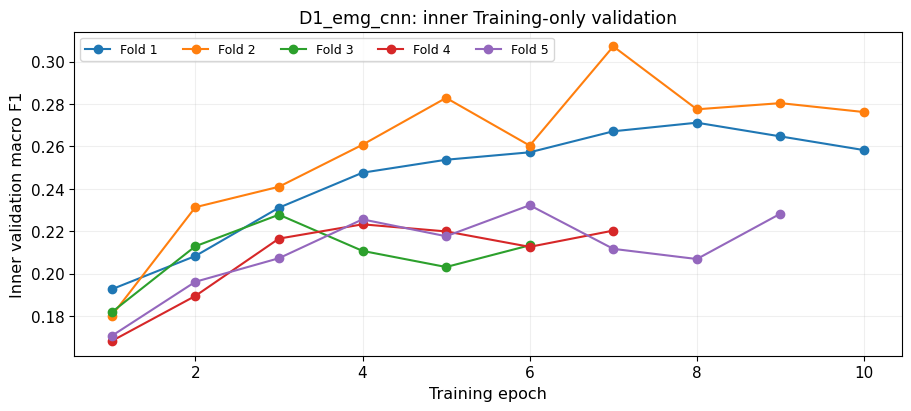

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.174204,8,44.294051
1,1,7,0.213393,7,35.528627
2,2,7,0.221516,3,21.583737
3,3,7,0.262976,4,24.811598
4,4,7,0.219284,6,31.397347


In [11]:
# ========================= 10. D1: sEMG-Only 1D-CNN ==========================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D1_emg_cnn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**11. D1: Acceleration-Only 1D-CNN**

The matched convolutional family receives **36 acceleration columns** on the published common sample-row grid. Native accelerometer sampling was slower than that grid, so the released adjacent rows do not constitute independent high-rate measurements.

**Compute:** When CUDA has sufficient free memory, the acceleration windows for each Training fold and its Training-only inner validation are normalised once and staged in GPU memory. Subsequent epochs reuse those same float32 windows instead of rereading the source files. If sufficient memory is unavailable, the existing streamed DataLoader remains the fallback. The original sample grid, participant assignments and maximum training epochs are unchanged. Setup, training and inner-validation durations are printed separately.


In [ ]:
# ===================== 11. D1: Acceleration-Only 1D-CNN ======================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D1_acc_cnn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))



Model: D1_acc_cnn | modality: Acceleration | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Data loader: acc only | workers=2 | pinned memory=True | batch size=96
  D1_acc_cnn | seed=42 | epoch 1/10 | loss=2.3320 | inner macro F1=0.0686 | 315.6 s


**12. D2: sEMG-Only Temporal CNN**

The residual temporal convolutional network uses dilated convolutional blocks on sEMG. It is compared against the other encoders on the same retained windows, common folds, training budget and fixed label definitions.


In [ ]:
# ====================== 12. D2: sEMG-Only Temporal CNN =======================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D2_emg_tcn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**13. D2: Acceleration-Only Temporal CNN**

The same residual TCN family processes the source-aligned acceleration sequence. Reporting fold-specific training times makes any modality-dependent runtime costs visible without changing the participant-independent evaluation.


In [ ]:
# ================== 13. D2: Acceleration-Only Temporal CNN ===================

# 1. Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D2_acc_tcn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**14. D3: sEMG-Only BiGRU**

The bidirectional gated recurrent network models temporal dependencies after pooling the sEMG time axis. Bidirectionality uses the complete offline window; it does not demonstrate causal or real-time operation.


In [ ]:
# ========================== 14. D3: sEMG-Only BiGRU ==========================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D3_emg_bigru", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**15. D3: Acceleration-Only BiGRU**

The acceleration BiGRU completes the six matched unimodal temporal experiments. Its participant-wise scores and source-aligned probabilities remain independent model evidence until the aggregation stage verifies that all five folds have completed.


In [ ]:
# ====================== 15. D3: Acceleration-Only BiGRU ======================

# Participant-Grouped Model Fit 
display(run_unimodal_arm(
    "D3_acc_bigru", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**16. Consolidate Complete Development Experiments**

Read the current model-specific probability arrays, per-participant metrics and prediction records. Validate exact source-window keys, folds, class order, primary seed and numerical completeness before combining any result.

The aggregated out-of-fold (OOF) arrays preserve the **original full `window_row` indexing** for Notebook 04. The strongest unimodal comparator is selected using equal-participant Development macro F1 only. Reserved Test rows remain unpopulated.


In [ ]:
# ================== 16. Consolidate Development Experiments ==================

probabilities, classical_metrics, neural_metrics, neural_history, chosen, summary = (
    consolidate_unimodal_outputs(
        index, dev, classes, output_dir=output_dir, folds=common_folds,
        seed=SEED, neural_settings={
            "epochs": NEURAL_EPOCHS,
            "patience": NEURAL_PATIENCE,
            "batch_size": NEURAL_BATCH_SIZE,
        },
    )
)
print("Development-selected unimodal comparator:", chosen)
display(summary)


**17. Select Neural Finalists for Seed Robustness**

Choose one neural model independently within each modality using Development participant-mean macro F1. Training seeds **43** and **44** repeat each selected model on the same grouped folds; these repeated fits are secondary stability evidence and must not be treated as additional independent participants.


In [ ]:
# ================== 17. Select Neural Robustness Finalists ===================

EXTRA_SEEDS = (43, 44)
emg_finalist, _ = select_model(
    neural_metrics, [name for name in UNIMODAL_MODELS if "_emg_" in name]
)
acc_finalist, _ = select_model(
    neural_metrics, [name for name in UNIMODAL_MODELS if "_acc_" in name]
)
print("sEMG finalist:", emg_finalist)
print("Acceleration finalist:", acc_finalist)


**18. Additional Seeds: Selected sEMG Model**

Repeat the Development-selected sEMG temporal architecture at seeds 43 and 44. Each run uses the same participant separation and Training-only normalisation; each seed/fold combination is recorded separately for stability analysis.


In [ ]:
# ===================== 18. sEMG Finalist Seed Robustness =====================

display(evaluate_finalist_seeds(
    emg_finalist, dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seeds=EXTRA_SEEDS, epochs=NEURAL_EPOCHS,
    patience=NEURAL_PATIENCE, batch_size=NEURAL_BATCH_SIZE,
))


**19. Additional Seeds: Selected Acceleration Model**

Apply the identical two extra seeds to the Development-selected acceleration model. Keep its fold-wise records separate from the sEMG experiment; aggregate the two finalists only after complete seed and fold coverage is verified.


In [ ]:
# ================= 19. Acceleration Finalist Seed Robustness =================

display(evaluate_finalist_seeds(
    acc_finalist, dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seeds=EXTRA_SEEDS, epochs=NEURAL_EPOCHS,
    patience=NEURAL_PATIENCE, batch_size=NEURAL_BATCH_SIZE,
))
display(consolidate_seed_robustness(
    (emg_finalist, acc_finalist), output_dir,
    folds=common_folds, seeds=EXTRA_SEEDS,
))


**20. Compare Unimodal Performance and Errors**

Compare classical and neural models using participant-balanced Development macro F1. The first figure summarises model scores and descriptive neural training loss, while the second shows the selected comparator's complete out-of-fold class confusion matrix.

The confusion matrix counts **windows**, whereas the primary model-selection metric weights **participants equally**. These distinct units must not be conflated; both plots concern Development data, not the reserved Test participants.


In [ ]:
# =============== 20. Development Comparison and Error Figures ================

# -------------------- 1. Participant-Balanced Model Scores -------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ranked = summary.iloc[::-1]
axes[0].barh(ranked.model_id, ranked.mean_subject_macro_f1)
axes[0].set(
    xlabel="Mean participant macro F1",
    title="Unimodal Development comparison",
)

# ----------------------- 2. Neural Optimisation History ----------------------
curve = neural_history.groupby("epoch", as_index=False).train_loss.mean()
axes[1].plot(curve.epoch, curve.train_loss, marker="o")
axes[1].set(
    xlabel="Training epoch", ylabel="Mean training loss",
    title="Neural optimisation (descriptive)",
)
for ax in axes:
    ax.grid(alpha=0.2)
save_figure(fig, output_dir / "03_learning_curves.png")
plt.show()

# --------------------- 3. Selected-Model Error Structure ---------------------
selected_rows = dev.sort_values("window_row")
selected_proba = probabilities[chosen][selected_rows.window_row.to_numpy(int)]
cm = confusion_matrix(
    selected_rows.label.to_numpy(int),
    predictions_from_probabilities(selected_proba, classes), labels=classes,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
image = ax.imshow(cm, aspect="auto")
ax.set(
    xlabel="Predicted corrected class", ylabel="True corrected class",
    title=f"Development OOF confusion: {chosen}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(image, ax=ax, label="Window count")
save_figure(fig, output_dir / "03_class_errors.png")
plt.show()


**21. Research Interpretation and Output Download**

The primary comparison uses the fixed source-defined E1 class set and identical participant-disjoint Development folds. Selected models are compared using the mean of participant-level macro F1; neural training histories and additional seeds provide complementary optimisation and stability evidence.

Notebook 04 consumes the matched OOF probability matrices and summary metrics to compare paired fusion against the Development-selected unimodal reference. The final cell lists the current Notebook 03 research products once through the Colab download helper.


In [ ]:
# ===================== 21. Research Outputs and Download =====================

download_outputs_from_colab(
    folder="multimodal_movement_learning/output",
    stage=f"{NOTEBOOK_NUMBER:02d}",
)
